In [1]:
import pandas as pd
df = pd.read_csv(r"C:\online_retail\data\raw\online_retail_II.csv")

In [4]:
df['Quantity'].describe()


count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64

In [6]:
df['Quantity'].dtype


dtype('int64')

In [7]:
df['Quantity'].isna().sum()

np.int64(0)

In [8]:
(df['Quantity'] < 0).sum(), (df['Quantity'] == 0).sum()

# What are the negatives?
neg = df[df['Quantity'] < 0]
neg['Invoice'].astype(str).str.startswith('C').mean()   # share that are cancellations
neg['Price'].eq(0).mean()                               # share that are adjustments

np.float64(0.1506318082788671)

In [9]:
sales = df[(df['Price'] > 0) & df['Customer ID'].notna() & (df['Quantity'] > 0)]
sales['Quantity'].quantile([.5, .9, .99, .999, 1])
sales.nlargest(10, 'Quantity')[['Invoice','StockCode','Description','Quantity','Price','Customer ID']]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940.0
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940.0


In [24]:
import pandas as pd

# 1. Filter valid positive sales records
sales = df[
    (df['Price'] > 0) &
    (df['Customer ID'].notna()) &
    (df['Quantity'] > 0)
].copy()

# 2. Calculate transaction amount
sales['Amount'] = sales['Quantity'] * sales['Price']

# 3. Get the top 10 transactions by quantity
top_quantity = sales.nlargest(10, 'Quantity')

top_quantity[
    ['Invoice', 'StockCode', 'Description',
     'Quantity', 'Price', 'Amount', 'Customer ID']
]

,Invoice,StockCode,Description,Quantity,Price,Amount,Customer ID
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902.0
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902.0
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902.0
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940.0
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940.0
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940.0
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,2500.0,17940.0
93677,498152,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,0.30,2836.8,13902.0


In [25]:
# Get invoice numbers from the top 10 transactions
top_invoices = top_quantity['Invoice'].unique()

# Display all products in those invoices
sales[sales['Invoice'].isin(top_invoices)][
    ['Invoice', 'StockCode', 'Description',
     'Quantity', 'Price', 'Amount', 'Customer ID']
].sort_values(
    ['Invoice', 'Quantity'],
    ascending=[True, False]
)

,Invoice,StockCode,Description,Quantity,Price,Amount,Customer ID
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902.0
90866,497946,47503E,ASS FLORAL PRINT SCISSORS,6696,0.15,1004.4,13902.0
90882,497946,20760,GARDEN PATH POCKET BOOK,4320,0.10,432.0,13902.0
90871,497946,20729,RED SPOTTY CANDY BAG,4200,0.15,630.0,13902.0
90864,497946,47504E,ENGLISH ROSE SCISSORS,4176,0.15,626.4,13902.0
90875,497946,20778,GARDEN PATH NOTEBOOK,3360,0.15,504.0,13902.0
90878,497946,20775,DAISY NOTEBOOK,3360,0.15,504.0,13902.0
90858,497946,85198,ASSORTED FARMYARD ANIMALS IN BUCKET,3312,0.30,993.6,13902.0
90876,497946,20777,CHRYSANTHEMUM NOTEBOOK,3200,0.15,480.0,13902.0
90879,497946,20774,GREEN FERN NOTEBOOK,3200,0.15,480.0,13902.0


In [26]:
# Calculate percentiles for positive quantities
sales['Quantity'].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.00])

0.500        5.0
0.750       12.0
0.900       24.0
0.950       36.0
0.990      128.0
0.999      576.0
1.000    19152.0
Name: Quantity, dtype: float64

In [27]:
Q1 = sales['Quantity'].quantile(0.25)
Q3 = sales['Quantity'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 2.0
Q3: 12.0
IQR: 10.0
Lower bound: -13.0
Upper bound: 27.0


In [28]:
print((sales['Quantity'] > 27).mean())                 # exact share flagged by IQR
print((sales['Quantity'] > 128).sum())                 # lines above the 99th percentile

big = sales[sales['Quantity'] > 576]                   # top 0.1%
print(big.groupby('Customer ID').size().sort_values(ascending=False).head(10))
print(big[['StockCode','Description','Quantity','Price']].sort_values('Quantity', ascending=False).head(15))

0.06452882327164026
7982
Customer ID
13902.0    47
17450.0    44
18102.0    42
17949.0    32
14277.0    31
13687.0    31
16422.0    30
16684.0    30
16754.0    29
13027.0    24
dtype: int64
       StockCode                          Description  Quantity  Price
90857      37410   BLACK AND WHITE PAISLEY FLOWER MUG     19152   0.10
127168     21091          SET/6 WOODLAND PAPER PLATES     12960   0.10
127166     21099          SET/6 STRAWBERRY PAPER CUPS     12960   0.10
127169     21085            SET/6 WOODLAND PAPER CUPS     12744   0.10
127167     21092        SET/6 STRAWBERRY PAPER PLATES     12480   0.10
135030     21981         PACK OF 12 WOODLAND TISSUES      10000   0.25
135028     21982             PACK OF 12 SUKI TISSUES      10000   0.25
135027     21984     PACK OF 12 PINK PAISLEY TISSUES      10000   0.25
135029     21980       PACK OF 12 RED SPOTTY TISSUES      10000   0.25
93677      85220      SMALL FAIRY CAKE FRIDGE MAGNETS      9456   0.30
432176     84347  ROTATING SI

In [29]:
# Count potential high-quantity outliers
quantity_outliers = sales[sales['Quantity'] > upper_bound]

total_rows = len(sales)
outlier_count = len(quantity_outliers)
outlier_percentage = (outlier_count / total_rows) * 100

print("Total sales records:", total_rows)
print("Potential quantity outliers:", outlier_count)
print("Percentage of potential outliers:", round(outlier_percentage, 2), "%")


Total sales records: 805547
Potential quantity outliers: 51981
Percentage of potential outliers: 6.45 %


In [30]:
# Define quantity ranges for analysis
bins = [27, 50, 100, 500, 1000, 5000, float('inf')]
labels = ['28–50', '51–100', '101–500',
          '501–1,000', '1,001–5,000', 'Above 5,000']

quantity_outliers = sales[sales['Quantity'] > 27].copy()

quantity_outliers['Quantity_Range'] = pd.cut(
    quantity_outliers['Quantity'],
    bins=bins,
    labels=labels
)

# Count records in each range
quantity_outliers['Quantity_Range'].value_counts(
    sort=False
).to_frame('Record_Count')

,Record_Count
Quantity_Range,
28–50,28606
51–100,13425
101–500,9003
"501–1,000",645
"1,001–5,000",274
"Above 5,000",28


In [11]:
pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 2.9 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.5 MB 3.4 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.5 MB 3.6 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.5 MB 3.7 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 3.6 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.5 MB 3.6 MB/s eta 0:00:02
   ---------------------- ----------------- 5.2/9.5 MB 3.6 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.5 MB 3.5 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 3.7 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.5 

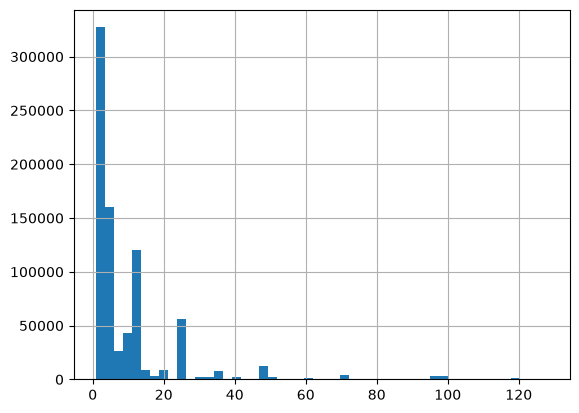

In [12]:
import matplotlib.pyplot as plt
sales[sales['Quantity'] <= sales['Quantity'].quantile(.99)]['Quantity'].hist(bins=50)
plt.show()

In [13]:
# Units per product
sales.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False).head(10)

# Typical basket: units per invoice
sales.groupby('Invoice')['Quantity'].sum().describe()

count    36969.000000
mean       289.598501
std       1235.793256
min          1.000000
25%         73.000000
50%        155.000000
75%        292.000000
max      87167.000000
Name: Quantity, dtype: float64

In [14]:
# Is each giant sale matched by a cancellation of the same size?
print(df[(df['Customer ID'].isin([16446, 12346])) & (df['Quantity'].abs() > 70000)]
      [['Invoice','StockCode','Quantity','InvoiceDate','Customer ID']])

         Invoice StockCode  Quantity          InvoiceDate  Customer ID
587080    541431     23166     74215  2011-01-18 10:01:00      12346.0
587085   C541433     23166    -74215  2011-01-18 10:17:00      12346.0
1065882   581483     23843     80995  2011-12-09 09:15:00      16446.0
1065883  C581484     23843    -80995  2011-12-09 09:27:00      16446.0


In [16]:
pairs = [('541431', 'C541433'), ('581483', 'C581484')]
drop_inv = [i for p in pairs for i in p]
df = df[~df['Invoice'].astype(str).isin(drop_inv)]

In [17]:
print(df[df['Invoice'].astype(str).isin(drop_inv)].groupby('Invoice').size())

Series([], dtype: int64)


In [20]:
import pandas as pd

d = df.copy()
d['InvoiceDate'] = pd.to_datetime(d['InvoiceDate'])      # the actual fix
d['Invoice'] = d['Invoice'].astype(str)
d['StockCode'] = d['StockCode'].astype(str).str.strip().str.upper()
d['is_cancel'] = d['Invoice'].str.startswith('C')

sales = d[~d['is_cancel'] & (d['Quantity'] > 0) & d['Customer ID'].notna()].copy()
sales['sale_date'] = sales['InvoiceDate']

cancels = d[d['is_cancel'] & d['Customer ID'].notna()].copy()
cancels['Quantity'] = -cancels['Quantity']

pairs = pd.merge_asof(
    cancels.sort_values('InvoiceDate'),
    sales.sort_values('InvoiceDate'),
    on='InvoiceDate',
    by=['Customer ID', 'StockCode', 'Quantity'],
    direction='backward',
    suffixes=('_cancel', '_sale'),
)

pairs = pairs.dropna(subset=['Invoice_sale'])
pairs['gap'] = pairs['InvoiceDate'] - pairs['sale_date']
pairs['value'] = pairs['Quantity'] * pairs['Price_cancel']

print(len(cancels), len(pairs))

18742 6740


In [21]:
quick = pairs[pairs['gap'] <= '1h']                  # likely entry mistakes
same_day = pairs[pairs['gap'] <= '1D']
print(len(quick), len(same_day))

cols = ['Customer ID','StockCode','Quantity','Price_cancel','value','Invoice_sale','Invoice_cancel','sale_date','gap']
print(quick.sort_values('value', ascending=False)[cols].head(20))

1111 1481
       Customer ID StockCode  Quantity  Price_cancel     value Invoice_sale  \
2738       12918.0         M         1      10953.50  10953.50       502263   
1614       17949.0         M         1       8985.60   8985.60       496115   
2617       15760.0         M         1       6958.17   6958.17       501768   
2618       15760.0         M         1       5795.87   5795.87       501768   
8308       17450.0     71477      1152          2.75   3168.00       529350   
5495       13734.0    84078A        85         34.95   2970.75       515296   
12343      12744.0         M         1       2382.92   2382.92       548820   
7468       14156.0         M         1       2366.40   2366.40       525498   
7879       15202.0         M         1       2225.17   2225.17       527258   
7881       15202.0         M         1       2225.17   2225.17       527271   
12344      12744.0         M         1       2053.07   2053.07       548820   
6561       15480.0         M         1    

In [22]:
sales['sale_idx'] = sales.index
cancels['cancel_idx'] = cancels.index

pairs = pd.merge_asof(
    cancels.sort_values('InvoiceDate'),
    sales.sort_values('InvoiceDate'),
    on='InvoiceDate',
    by=['Customer ID', 'StockCode', 'Quantity'],
    direction='backward',
    suffixes=('_cancel', '_sale'),
).dropna(subset=['Invoice_sale'])

pairs['gap'] = pairs['InvoiceDate'] - pairs['sale_date']

quick = pairs[(pairs['gap'] <= '1h') & (pairs['Price_cancel'] == pairs['Price_sale'])]
quick = quick.drop_duplicates('sale_idx')          # one cancel per sale
quick = quick[quick['StockCode'] != 'M']           # handle manual lines separately

print(len(quick))

drop_idx = list(quick['sale_idx'].astype(int)) + list(quick['cancel_idx'].astype(int))
df_clean = df.drop(index=drop_idx)

991


In [23]:
# 1) Every pair really nets to zero
chk = quick.assign(net=(quick['Quantity'] * quick['Price_sale']) - (quick['Quantity'] * quick['Price_cancel']))
print(chk['net'].abs().sum())            # should be 0

# 2) No row appears twice in the drop list
print(len(drop_idx), len(set(drop_idx)))  # the two numbers should match

0.0
1982 1982
